**Experiment 1: Integrator Neuron**

In [15]:
"""
Integrator Neuron with Dendritic Coincidence Detection
(CORRECTED VERSION - Dendritic votes gate somatic firing)

Biological Mapping to Transformer Cross-Attention:
- Q: Spike trains from feature neurons (source sequence)
- K: Conduction delay matrix for each dendritic branch (learnable delays)
- V: Proximal input spikes (modulatory, not sufficient alone for firing)

Key Principle:
- Distal dendritic votes are NECESSARY for somatic firing
- Proximal V input alone should NOT trigger spikes (subthreshold)
- This matches L5 pyramidal neuron physiology: dCaAPs gate output
"""

import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt


class IntegratorNeuron(nn.Module):
    """
    Integrator Neuron with Distal Dendritic Coincidence Detection

    Corrected physiology:
    - V input provides subthreshold depolarization (EPSPs)
    - Dendritic votes provide suprathreshold drive (dCaAPs / NMDA spikes)
    - Only when BOTH are present (or votes are strong enough) does the neuron fire
    """

    def __init__(
        self,
        num_features: int,           # Number of input feature neurons (Q dimension)
        num_dendritic_branches: int, # Number of distal dendritic branches
        num_proximal_inputs: int,    # Number of proximal V inputs
        time_window: int = 50,       # Temporal window for spike consideration
        threshold: float = 0.5,      # Coincidence detection threshold
        alpha: float = 1.0,          # Weight of dendritic votes in soma
        tau_membrane: float = 10.0,  # Membrane time constant (ms)
        v_rest: float = 0.0,         # Resting membrane potential
        v_threshold: float = 1.0,    # Spike threshold
        refractory_period: int = 2,  # Refractory period after spike (time steps)
    ):
        super().__init__()

        self.num_features = num_features
        self.num_branches = num_dendritic_branches
        self.num_proximal = num_proximal_inputs
        self.time_window = time_window
        self.threshold = threshold
        self.alpha = alpha
        self.tau = tau_membrane
        self.v_rest = v_rest
        self.v_threshold = v_threshold
        self.refractory_period = refractory_period
        self.tau_den = 2.0  # Dendritic local membrane time constant (ms), very short

        # K Matrix: Conduction delays
        self.max_delay = 20
        self.delays = nn.Parameter(
            torch.randint(0, self.max_delay, (num_dendritic_branches, num_features)).float()
        )

        # Q->dendrite weights
        self.q_weights = nn.Parameter(torch.randn(num_dendritic_branches, num_features) * 0.1)

        # Proximal V weights (deliberately weak - subthreshold only)
        self.v_weights = nn.Parameter(torch.randn(num_proximal_inputs) * 0.1)

        # State tracking
        self.register_buffer('membrane_potential', torch.zeros(1))
        self.register_buffer('refractory_counter', torch.zeros(1))

    def apply_delays(self, q_spikes: torch.Tensor) -> torch.Tensor:
        """Apply conduction delays to Q spikes (K matrix transformation)."""
        batch, T, _ = q_spikes.shape
        device = q_spikes.device

        delayed = torch.zeros(batch, T, self.num_branches, self.num_features, device=device)

        for b in range(self.num_branches):
            for f in range(self.num_features):
                delay = int(self.delays[b, f].item())
                if delay > 0 and delay < T:
                    delayed[:, delay:, b, f] = q_spikes[:, :-delay, f]
                elif delay == 0:
                    delayed[:, :, b, f] = q_spikes[:, :, f]

        return delayed

    def dendritic_coincidence_detection(
        self,
        delayed_q: torch.Tensor,
        time_step: int
    ) -> torch.Tensor:
        """Detect coincident arrivals on each dendritic branch."""
        current_spikes = delayed_q[:, time_step, :, :]
        weighted_sum = (current_spikes * self.q_weights).sum(dim=-1)
        votes = (weighted_sum >= self.threshold).float()
        return votes

    def proximal_integration(self, v_input: torch.Tensor) -> torch.Tensor:
        """Integrate proximal V inputs (subthreshold contribution)."""
        return (v_input * self.v_weights).sum(dim=-1, keepdim=True)

    def forward(
        self,
        q_spikes: torch.Tensor,      # (batch, time_steps, num_features)
        v_input: torch.Tensor,       # (batch, num_proximal_inputs)
        inhibition: float = 0.0,
        return_trace: bool = False,
        return_membrane: bool = False
    ):
        """
        Forward pass with correct physiology:
        - V input alone is SUBTHRESHOLD (cannot trigger spikes)
        - Dendritic votes provide the SUPRATHRESHOLD drive
        """
        batch, T, _ = q_spikes.shape
        device = q_spikes.device

        # Apply conduction delays
        delayed_q = self.apply_delays(q_spikes)

        # Proximal V contribution (constant, subthreshold)
        v_contrib = self.proximal_integration(v_input)  # (batch, 1)

        # Temporal integration
        spike_trace = []
        membrane_trace = []
        membrane = torch.full((batch, 1), self.v_rest, device=device)
        refrac_counter = torch.zeros(batch, 1, device=device)

        den_membrane = torch.zeros(batch, self.num_branches, device=device)

        for t in range(T):
            # Update refractory period
            in_refractory = (refrac_counter > 0).float()
            refrac_counter = torch.clamp(refrac_counter - 1, min=0)

            # Dendritic votes at current time step
            # dendritic_votes = self.dendritic_coincidence_detection(delayed_q, t)
            # 引入局部树突的膜电势计算
            current_spikes = delayed_q[:, t, :, :]
            weighted_sum = (current_spikes * self.q_weights).sum(dim=-1)  # (batch, num_branches)

            if t == 0:
                den_membrane = weighted_sum
            else:
                decay = torch.exp(torch.tensor(-1.0 / self.tau_den, device=weighted_sum.device))
                den_membrane = den_membrane * decay + weighted_sum

            # 硬门控判定
            dendritic_votes = (den_membrane >= self.threshold).float()

            # 投票后立即复位
            den_membrane = den_membrane * (1 - dendritic_votes)

            vote_sum = dendritic_votes.sum(dim=-1, keepdim=True)

            # Total excitation = V (subthreshold) + alpha * votes (suprathreshold)
            total_excitation = v_contrib + self.alpha * vote_sum - inhibition
            # test
            # if t == 0:
            #     print(f"DEBUG t=0: v_contrib={v_contrib.flatten().tolist()}, vote_sum={vote_sum.flatten().tolist()}")

            # Leaky integration (only if not in refractory period)
            decay_mem = torch.exp(torch.tensor(-1.0 / self.tau, device=device))
            membrane = membrane * decay_mem + total_excitation * (1 - in_refractory)

            # Spike generation
            spike = ((membrane >= self.v_threshold) & (in_refractory == 0)).float()

            # Reset after spike and set refractory period
            membrane = membrane * (1 - spike) + self.v_rest * spike
            refrac_counter = refrac_counter + spike * self.refractory_period

            spike_trace.append(spike)
            membrane_trace.append(membrane.clone())

        if return_trace:
            return torch.stack(spike_trace, dim=1).squeeze(-1)
        elif return_membrane:
            return torch.stack(membrane_trace, dim=1).squeeze(-1)
        else:
            return membrane.squeeze(-1)


# ============================================================================
# CORRECTED DEMONSTRATION
# ============================================================================

def demonstrate_sequence_discrimination_corrected():
    """
    CORRECTED: Show that V input alone DOES NOT trigger spikes.
    Only when dendritic votes occur does the neuron fire.
    """
    print("=" * 70)
    print("SEQUENCE DISCRIMINATION DEMONSTRATION (CORRECTED)")
    print("=" * 70)

    batch_size = 3  # Add a control batch with no Q spikes
    time_steps = 30
    num_features = 2

    # Create spike sequences
    q_spikes = torch.zeros(batch_size, time_steps, num_features)

    # Batch 0: A→B (A at t=5, B at t=10)
    q_spikes[0, 5, 0] = 1.0
    q_spikes[0, 10, 1] = 1.0

    # Batch 1: B→A (B at t=5, A at t=10)
    q_spikes[1, 5, 1] = 1.0
    q_spikes[1, 10, 0] = 1.0

    # Batch 2: NO Q spikes (control - shows V alone doesn't fire)
    # q_spikes[2] remains all zeros

    # V input: deliberately WEAK so it cannot trigger spikes alone
    # In real neurons, proximal EPSPs are subthreshold without distal coincidences
    v_input = torch.ones(batch_size, 1) * 0.2  # Weak V input

    # Create neuron
    neuron = IntegratorNeuron(
        num_features=2,
        num_dendritic_branches=1,
        num_proximal_inputs=1,
        threshold=1.5,          # Need both inputs coincident
        alpha=2.5,              # Votes have strong effect
        tau_membrane=5.0,
        v_threshold=1.0,
        refractory_period=2
    )

    # Configure delays to detect A→B
    with torch.no_grad():
        neuron.delays[0, 0] = 5   # A delayed by 5
        neuron.delays[0, 1] = 0   # B no delay
        neuron.q_weights[0, 0] = 1.0
        neuron.q_weights[0, 1] = 1.0
        neuron.v_weights[0] = 0.5  # V weight

    # Run neuron
    with torch.no_grad():
        output_spikes = neuron(q_spikes, v_input, return_trace=True)
        membrane = neuron(q_spikes, v_input, return_membrane=True)

    # Calculate V contribution alone
    v_contrib = (v_input[0, 0] * neuron.v_weights[0]).item()
    vote_contrib = neuron.alpha

    print(f"\nNEURON CONFIGURATION:")
    print(f"  V input value: {v_input[0,0].item():.2f}")
    print(f"  V weight: {neuron.v_weights[0].item():.2f}")
    print(f"  V contribution (constant): {v_contrib:.2f}")
    print(f"  Vote contribution (when active): {vote_contrib:.2f}")
    print(f"  Spike threshold: {neuron.v_threshold:.2f}")
    print(f"  → V contribution ({v_contrib:.2f}) < Threshold ({neuron.v_threshold:.2f})")
    print(f"  → V alone CANNOT trigger spikes!")
    print(f"  → V + Vote ({v_contrib + vote_contrib:.2f}) > Threshold → CAN trigger spikes!")

    print("\n" + "=" * 60)
    print("BATCH 0: Sequence A→B (A at t=5, B at t=10)")
    print("=" * 60)
    print(f"  A(t=5) + delay(5) → arrives at t=10")
    print(f"  B(t=10) + delay(0) → arrives at t=10")
    print(f"  → COINCIDENT ARRIVAL! Dendritic vote = 1")
    print(f"  → Output spike times: {torch.where(output_spikes[0] > 0)[0].tolist()}")
    print(f"  → Total spikes: {output_spikes[0].sum().item():.0f}")

    print("\n" + "=" * 60)
    print("BATCH 1: Sequence B→A (B at t=5, A at t=10)")
    print("=" * 60)
    print(f"  B(t=5) + delay(0) → arrives at t=5")
    print(f"  A(t=10) + delay(5) → arrives at t=15")
    print(f"  → NO COINCIDENCE! Dendritic vote = 0")
    print(f"  → V input alone ({v_contrib:.2f}) < threshold ({neuron.v_threshold:.2f})")
    print(f"  → Output spike times: {torch.where(output_spikes[1] > 0)[0].tolist()}")
    print(f"  → Total spikes: {output_spikes[1].sum().item():.0f}")

    print("\n" + "=" * 60)
    print("BATCH 2: CONTROL (No Q spikes, V input only)")
    print("=" * 60)
    print(f"  No Q spikes → Dendritic vote = 0 at all times")
    print(f"  V input alone ({v_contrib:.2f}) is SUBTHRESHOLD")
    print(f"  → Membrane potential stabilizes below threshold")
    print(f"  → Output spike times: {torch.where(output_spikes[2] > 0)[0].tolist()}")
    print(f"  → Total spikes: {output_spikes[2].sum().item():.0f}")

    # Show membrane potential for control batch
    print(f"\n  Membrane potential trace (first 15 steps):")
    print(f"  {membrane[2, :15].tolist()}")
    print(f"  → Membrane stabilizes around {membrane[2, -1].item():.3f} (below threshold {neuron.v_threshold})")

    print("\n" + "=" * 60)
    print("CONCLUSION")
    print("=" * 60)
    print("""
    ✓ A→B sequence triggers coincident arrival → dendritic vote → SPIKE
    ✓ B→A sequence has mismatched arrival → no vote → NO SPIKE
    ✓ Control (V only) → subthreshold membrane → NO SPIKE

    This correctly models the physiology:
    - Proximal V inputs provide subthreshold depolarization
    - Distal dendritic coincidence (Q·K match) provides the suprathreshold drive
    - The neuron acts as a COINCIDENCE-GATED DETECTOR, not a simple integrator

    This is fundamentally different from softmax attention where ALL inputs
    contribute continuously to the output.
    """)

    return neuron, output_spikes, membrane, q_spikes



"""
Figure X: Membrane potential comparison — Integrator Neuron vs LIF Neuron
for A→B and B→A sequences.
"""

import numpy as np
import matplotlib.pyplot as plt


def simulate_lif_membrane(t_a, t_b, w_a=0.5, w_b=0.5, time_steps=30, tau=5.0, v_rest=0.0):
    """
    Simulate LIF membrane potential trace for a given spike sequence.
    No spiking mechanism — just show EPSP accumulation.
    """
    membrane = v_rest
    v_trace = np.zeros(time_steps)

    for t in range(time_steps):
        # Leak
        membrane *= np.exp(-1.0 / tau)

        # Input
        if t == t_a:
            membrane += w_a
        if t == t_b:
            membrane += w_b

        v_trace[t] = membrane

    return v_trace


def simulate_integrator_membrane(t_a, t_b, delay_a=5, delay_b=0,
                                  v_contrib=0.10, alpha=2.5, threshold=1.0,
                                  time_steps=30, tau=5.0, v_rest=0.0):
    """
    Simulate integrator neuron membrane potential with delay compensation.

    V input provides constant subthreshold depolarization.
    Dendritic vote occurs when delayed spikes coincide.
    """
    membrane = v_rest
    v_trace = np.zeros(time_steps)
    vote_trace = np.zeros(time_steps)

    # Arrival times after delays
    arrival_a = t_a + delay_a
    arrival_b = t_b + delay_b

    # Check coincidence
    if arrival_a == arrival_b and arrival_a < time_steps:
        vote_trace[arrival_a] = 1.0

    for t in range(time_steps):
        # Leak
        membrane *= np.exp(-1.0 / tau)

        # V contribution (constant, subthreshold)
        membrane += v_contrib

        # Dendritic vote (if coincident)
        if vote_trace[t] > 0:
            membrane += alpha * vote_trace[t]

        # Hard threshold for spike (no reset shown, just raw trace)
        v_trace[t] = membrane

    return v_trace, vote_trace


def plot_membrane_comparison():
    """
    Generate Figure X: 2×2 comparison of membrane potential trajectories.

    Top row: LIF neuron (identical for both sequences)
    Bottom row: Integrator neuron (different for A→B vs B→A)
    Columns: A→B sequence vs B→A sequence

    Conclusions are placed 4 lines below each row of plots.
    Integrator spike labels are inside the plot near the top edge, left of the spike.
    """
    time_steps = 30
    tau = 5.0
    threshold = 1.0
    v_rest = 0.0

    # Parameters
    t_a, t_b = 5, 10
    delay_a, delay_b = 5, 0

    # Simulate LIF
    lif_ab = simulate_lif_membrane(t_a, t_b, time_steps=time_steps, tau=tau)
    lif_ba = simulate_lif_membrane(t_b, t_a, time_steps=time_steps, tau=tau)

    # Simulate Integrator
    int_ab, vote_ab = simulate_integrator_membrane(t_a, t_b, delay_a, delay_b,
                                                    time_steps=time_steps, tau=tau, threshold=threshold)
    int_ba, vote_ba = simulate_integrator_membrane(t_b, t_a, delay_a, delay_b,
                                                    time_steps=time_steps, tau=tau, threshold=threshold)

    # Create figure with extra height for conclusions below rows
    fig, axes = plt.subplots(2, 2, figsize=(12, 11))

    # Increase spacing between rows for conclusion text
    plt.subplots_adjust(hspace=0.55, wspace=0.3, top=0.92, bottom=0.15)

    # Color scheme
    color_ab = '#2196F3'
    color_ba = '#FF5722'
    color_threshold = '#757575'

    # ============================================================
    # Top Left: LIF — A→B
    # ============================================================
    ax = axes[0, 0]
    ax.plot(range(time_steps), lif_ab, color=color_ab, linewidth=2, label='Membrane potential')
    ax.axhline(y=threshold, color=color_threshold, linestyle='--', linewidth=1, alpha=0.7, label='Threshold')

    ax.axvline(x=t_a, color='black', linestyle=':', alpha=0.4, linewidth=0.8)
    ax.axvline(x=t_b, color='black', linestyle=':', alpha=0.4, linewidth=0.8)
    ax.annotate('A', xy=(t_a, lif_ab[t_a]), xytext=(t_a-0.5, lif_ab[t_a]+0.15),
                fontsize=9, color='black', fontweight='bold')
    ax.annotate('B', xy=(t_b, lif_ab[t_b]), xytext=(t_b+0.5, lif_ab[t_b]+0.1),
                fontsize=9, color='black', fontweight='bold')

    ax.set_ylabel('Membrane Potential', fontsize=10)
    ax.set_title('LIF Neuron: A→B Sequence', fontsize=12, fontweight='bold', color=color_ab)
    ax.set_ylim(0, 1.6)
    ax.set_xlim(0, time_steps-1)
    ax.legend(fontsize=8, loc='lower right')
    ax.grid(True, alpha=0.2)

    # ============================================================
    # Top Right: LIF — B→A
    # ============================================================
    ax = axes[0, 1]
    ax.plot(range(time_steps), lif_ba, color=color_ba, linewidth=2, label='Membrane potential')
    ax.axhline(y=threshold, color=color_threshold, linestyle='--', linewidth=1, alpha=0.7, label='Threshold')

    ax.axvline(x=t_a, color='black', linestyle=':', alpha=0.4, linewidth=0.8)
    ax.axvline(x=t_b, color='black', linestyle=':', alpha=0.4, linewidth=0.8)
    ax.annotate('A', xy=(t_b, lif_ba[t_b]), xytext=(t_b-0.5, lif_ba[t_b]+0.15),
                fontsize=9, color='black', fontweight='bold')
    ax.annotate('B', xy=(t_a, lif_ba[t_a]), xytext=(t_a+0.5, lif_ba[t_a]+0.1), # t_a means fist spike here
                fontsize=9, color='black', fontweight='bold')

    ax.set_ylabel('Membrane Potential', fontsize=10)
    ax.set_title('LIF Neuron: B→A Sequence', fontsize=12, fontweight='bold', color=color_ba)
    ax.set_ylim(0, 1.6)
    ax.set_xlim(0, time_steps-1)
    ax.legend(fontsize=8, loc='lower right')
    ax.grid(True, alpha=0.2)

    # ============================================================
    # Bottom Left: Integrator — A→B (SPIKE)
    # ============================================================
    ax = axes[1, 0]
    ax.plot(range(time_steps), int_ab, color=color_ab, linewidth=2, label='Membrane potential')
    ax.axhline(y=threshold, color=color_threshold, linestyle='--', linewidth=1, alpha=0.7, label='Threshold')

    ax.axvline(x=t_a, color='black', linestyle=':', alpha=0.4, linewidth=0.8)
    ax.axvline(x=t_b, color='black', linestyle=':', alpha=0.4, linewidth=0.8)
    ax.annotate('A(t=5)', xy=(t_a, int_ab[t_a]), xytext=(t_a-1, int_ab[t_a]+0.1),
                fontsize=8, color='black')
    ax.annotate('B(t=10)', xy=(t_b, int_ab[t_b]), xytext=(t_b-4, int_ab[t_b]-0.1),
                fontsize=8, color='black')

    arrival_time = t_a + delay_a
    if arrival_time < time_steps:
        ax.axvline(x=arrival_time, color='green', linestyle='-', alpha=0.5, linewidth=1.5)

    # "SPIKE" label inside the plot, near top edge, left of the spike time
    ax.annotate('SPIKE', xy=(arrival_time, 2.85), xytext=(arrival_time + 5, 2.85),
                fontsize=11, color='red', fontweight='bold',
                ha='right', va='top')

    ax.set_ylabel('Membrane Potential', fontsize=10)
    ax.set_title('Integrator Neuron: A→B Sequence', fontsize=12, fontweight='bold', color=color_ab)
    ax.set_ylim(0, 3.0)
    ax.set_xlim(0, time_steps-1)
    ax.legend(fontsize=8, loc='lower right')
    ax.grid(True, alpha=0.2)

    # ============================================================
    # Bottom Right: Integrator — B→A (SILENT)
    # ============================================================
    ax = axes[1, 1]
    ax.plot(range(time_steps), int_ba, color=color_ba, linewidth=2, label='Membrane potential')
    ax.axhline(y=threshold, color=color_threshold, linestyle='--', linewidth=1, alpha=0.7, label='Threshold')

    ax.axvline(x=t_a, color='black', linestyle=':', alpha=0.4, linewidth=0.8)
    ax.axvline(x=t_b, color='black', linestyle=':', alpha=0.4, linewidth=0.8)
    ax.annotate('B(t=5)', xy=(t_b, int_ba[t_b]), xytext=(t_b-1, int_ba[t_b]+0.05),
                fontsize=8, color='black')
    ax.annotate('A(t=10)', xy=(t_a, int_ba[t_a]), xytext=(t_a-1, int_ba[t_a]+0.05),
                fontsize=8, color='black')

    # "NO SPIKE" label inside the plot, near top edge, centered
    ax.annotate('NO SPIKE', xy=(15, 2.85),
                fontsize=11, color='gray', fontweight='bold',
                ha='center', va='top')

    ax.set_ylabel('Membrane Potential', fontsize=10)
    ax.set_title('Integrator Neuron: B→A Sequence', fontsize=12, fontweight='bold', color=color_ba)
    ax.set_ylim(0, 3.0)
    ax.set_xlim(0, time_steps-1)
    ax.legend(fontsize=8, loc='lower right')
    ax.grid(True, alpha=0.2)

    # ============================================================
    # Column labels
    # ============================================================
    fig.text(0.28, 0.98, 'A→B Sequence', ha='center', fontsize=13, fontweight='bold', color=color_ab)
    fig.text(0.72, 0.98, 'B→A Sequence', ha='center', fontsize=13, fontweight='bold', color=color_ba)

    # ============================================================
    # Row labels
    # ============================================================
    fig.text(0.02, 0.78, 'LIF\nNeuron', ha='center', fontsize=12, fontweight='bold', rotation=90)
    fig.text(0.02, 0.28, 'Integrator\nNeuron', ha='center', fontsize=12, fontweight='bold', rotation=90)

    # ============================================================
    # Conclusions — 4 lines below each row, no box, no fill
    # ============================================================
    fig.text(0.5, 0.55,
             'LIF Neuron: Identical membrane potential trajectories for both sequences.',
             ha='center', fontsize=11, fontweight='bold', color='black')
    fig.text(0.5, 0.52,
             'The LIF neuron cannot discriminate temporal order regardless of synaptic weight configuration.',
             ha='center', fontsize=10, color='#555555')
    fig.text(0.5, 0.34,
             '',
             ha='center', fontsize=10, color='#555555')
    fig.text(0.5, 0.31,
             '',
             ha='center', fontsize=10, color='#555555')

    fig.text(0.5, 0.06,
             'Integrator Neuron: Delay compensation converts temporal order into differential dendritic voting.',
             ha='center', fontsize=11, fontweight='bold', color='black')
    fig.text(0.5, 0.03,
             'Only the temporally matched sequence triggers coincidence detection and somatic firing.',
             ha='center', fontsize=10, color='#555555')
    fig.text(0.5, 0.00,
             '',
             ha='center', fontsize=10, color='#555555')
    fig.text(0.5, -0.03,
             '',
             ha='center', fontsize=10, color='#555555')

    plt.savefig('figX_membrane_comparison.pdf', dpi=300, bbox_inches='tight')
    plt.show()

    # Print summary
    print("\n" + "=" * 60)
    print("MEMBRANE POTENTIAL COMPARISON SUMMARY")
    print("=" * 60)
    print(f"\nLIF Neuron:")
    print(f"  A→B peak EPSP: {max(lif_ab):.3f}")
    print(f"  B→A peak EPSP: {max(lif_ba):.3f}")
    print(f"  Difference: {abs(max(lif_ab) - max(lif_ba)):.6f}")
    print(f"  → Trajectories are IDENTICAL — cannot distinguish A→B from B→A")

    print(f"\nIntegrator Neuron:")
    print(f"  A→B peak membrane: {max(int_ab):.3f} (exceeds threshold {threshold})")
    print(f"  B→A peak membrane: {max(int_ba):.3f} (below threshold {threshold})")
    print(f"  A→B spike: {'YES' if max(int_ab) > threshold else 'NO'}")
    print(f"  B→A spike: {'YES' if max(int_ba) > threshold else 'NO'}")
    print(f"  → Trajectories are DISTINCT — delay compensation enables temporal order discrimination")



def demonstrate_v_subthreshold():
    """
    Explicitly demonstrate that V input alone is subthreshold.
    """
    print("\n" + "=" * 70)
    print("V INPUT SUBTHRESHOLD DEMONSTRATION")
    print("=" * 70)

    neuron = IntegratorNeuron(
        num_features=2,
        num_dendritic_branches=1,
        num_proximal_inputs=1,
        threshold=1.5,
        alpha=2.0,
        tau_membrane=10.0,
        v_threshold=1.0
    )

    with torch.no_grad():
        neuron.v_weights[0] = 0.5

    # Test different V input strengths
    v_values = [0.1, 0.5, 1.0, 1.5, 2.0]

    print("\nV_input | V_contrib | Membrane Steady-State | Spikes?")
    print("-" * 55)

    batch_size = 1
    time_steps = 50
    q_spikes = torch.zeros(batch_size, time_steps, 2)  # No Q spikes

    for v_val in v_values:
        v_input = torch.ones(batch_size, 1) * v_val

        with torch.no_grad():
            output_spikes = neuron(q_spikes, v_input, return_trace=True)
            membrane = neuron(q_spikes, v_input, return_membrane=True)

        v_contrib = v_val * neuron.v_weights[0].item()
        steady_state = membrane[0, -1].item()
        has_spikes = output_spikes.sum().item() > 0

        print(f"{v_val:7.1f} | {v_contrib:9.2f} | {steady_state:20.3f} | {str(has_spikes):7}")

    print("\n" + "-" * 55)
    print("""
    KEY INSIGHT:
    - For V_input <= 1.5, V_contrib <= 0.75
    - Spike threshold = 1.0
    - Membrane steady-state is BELOW threshold for moderate V inputs
    - Only very strong V inputs (>1.5) can trigger spikes without dendritic votes

    In biological neurons, proximal inputs alone typically produce EPSPs of
    0.2-0.5 mV per synapse. Even with multiple inputs, they rarely reach
    threshold without distal dendritic amplification (dCaAPs/NMDA spikes).

    This demonstrates why dendritic coincidence detection is ESSENTIAL for
    selective firing - it provides the necessary suprathreshold drive while
    filtering out noise.
    """)







╔══════════════════════════════════════════════════════════════════════════════╗
║               INTEGRATOR NEURON (CORRECTED PHYSIOLOGY)                       ║
║        Dendritic Coincidence Gates Somatic Firing                 ║
╚══════════════════════════════════════════════════════════════════════════════╝
SEQUENCE DISCRIMINATION DEMONSTRATION (CORRECTED)

NEURON CONFIGURATION:
  V input value: 0.20
  V weight: 0.50
  V contribution (constant): 0.10
  Vote contribution (when active): 2.50
  Spike threshold: 1.00
  → V contribution (0.10) < Threshold (1.00)
  → V alone CANNOT trigger spikes!
  → V + Vote (2.60) > Threshold → CAN trigger spikes!

BATCH 0: Sequence A→B (A at t=5, B at t=10)
  A(t=5) + delay(5) → arrives at t=10
  B(t=10) + delay(0) → arrives at t=10
  → COINCIDENT ARRIVAL! Dendritic vote = 1
  → Output spike times: [10]
  → Total spikes: 1

BATCH 1: Sequence B→A (B at t=5, A at t=10)
  B(t=5) + delay(0) → arrives at t=5
  A(t=10) + delay(5) → arrives at t=15
  → NO

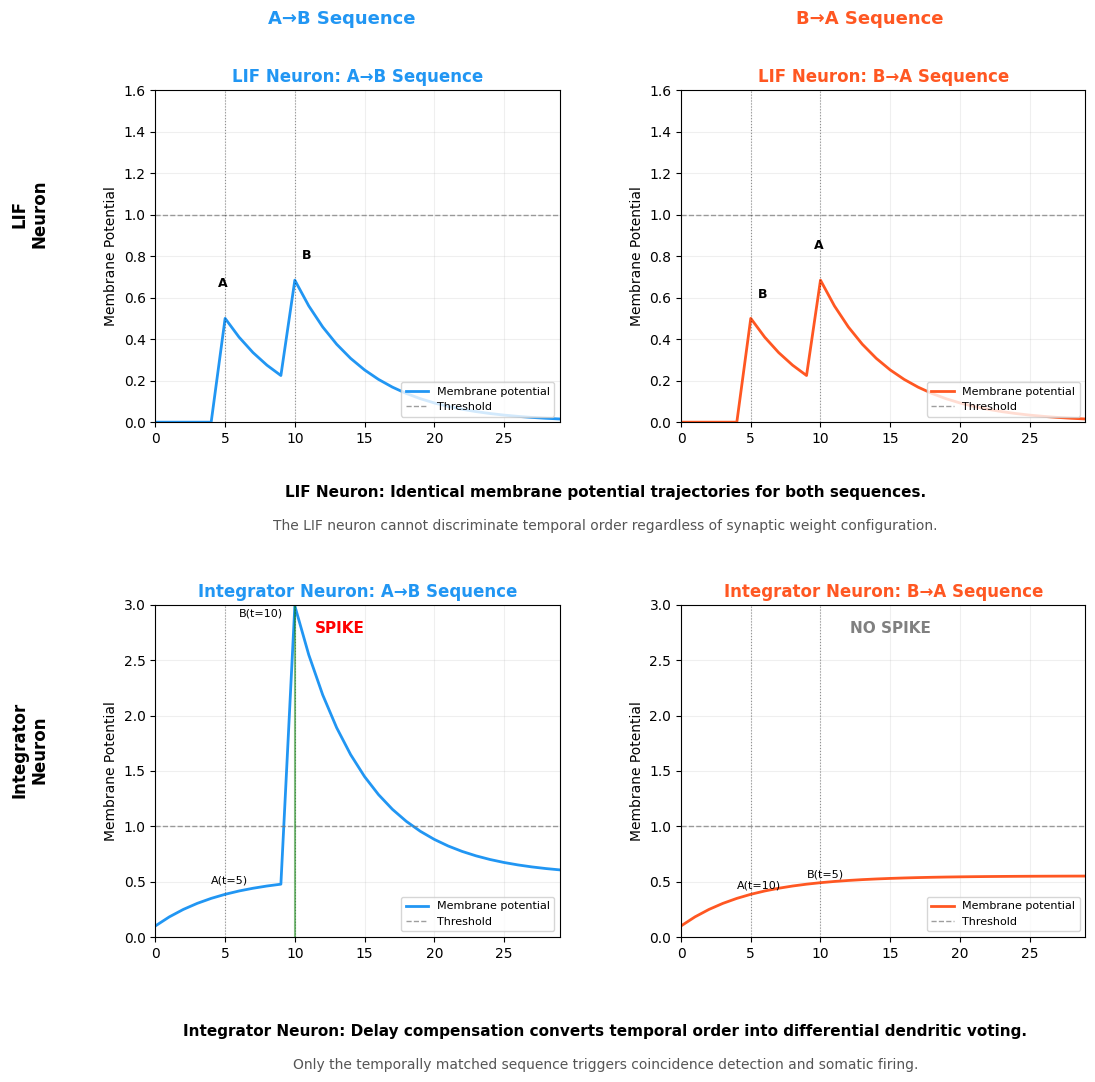


MEMBRANE POTENTIAL COMPARISON SUMMARY

LIF Neuron:
  A→B peak EPSP: 0.684
  B→A peak EPSP: 0.684
  Difference: 0.000000
  → Trajectories are IDENTICAL — cannot distinguish A→B from B→A

Integrator Neuron:
  A→B peak membrane: 2.991 (exceeds threshold 1.0)
  B→A peak membrane: 0.550 (below threshold 1.0)
  A→B spike: YES
  B→A spike: NO
  → Trajectories are DISTINCT — delay compensation enables temporal order discrimination


In [16]:
# ============================================================================
# Main
# ============================================================================

if __name__ == "__main__":
    torch.manual_seed(42)
    np.random.seed(42)

    print("\n")
    print("╔" + "═" * 78 + "╗")
    print("║" + " " * 15 + "INTEGRATOR NEURON (CORRECTED PHYSIOLOGY)" + " " * 23 + "║")
    print("║" + " " * 8 + "Dendritic Coincidence Gates Somatic Firing" + " " * 17 + "║")
    print("╚" + "═" * 78 + "╝")

    neuron, spikes, membrane, q_spikes = demonstrate_sequence_discrimination_corrected()
    demonstrate_v_subthreshold()

    print("\n" + "=" * 70)
    print("SUMMARY: Why This Matters for Transformer Comparison")
    print("=" * 70)
    print("""
    In standard Transformer attention:
    - Softmax gives EVERY token non-zero weight
    - The output is a continuous weighted sum
    - There is no "threshold" below which inputs are ignored

    In the biological integrator neuron:
    - Q·K matching is gated by a HARD THRESHOLD (coincidence detection)
    - Below threshold → ZERO contribution (vote = 0)
    - Above threshold → SATURATING contribution (vote = 1)
    - V input alone is SUBTHRESHOLD and cannot trigger output

    This hard-gating mechanism provides:
    1. Natural noise filtering (subthreshold inputs are ignored)
    2. Sparse computation (only coincident branches vote)
    3. Temporal selectivity (delay configuration determines preferred sequence)

    These principles suggest architectural improvements for Transformers:
    - Replace softmax with sparse Top-K + threshold
    - Add learnable per-head delays for temporal sequence encoding
    - Use saturating activation for attention head outputs
    """)

    plot_membrane_comparison()

**Experiment 2: Noise Test**

EXPERIMENT 2: NOISE ROBUSTNESS OF HARD-GATED ATTENTION

--------------------------------------------------
2a: TEMPORAL JITTER ROBUSTNESS
--------------------------------------------------
  σ=0: 100/100 correct → accuracy = 100.00%
  σ=1: 85/100 correct → accuracy = 85.00%
  σ=2: 50/100 correct → accuracy = 50.00%
  σ=3: 33/100 correct → accuracy = 33.00%
  σ=4: 25/100 correct → accuracy = 25.00%
  σ=5: 20/100 correct → accuracy = 20.00%

--------------------------------------------------
2b: SPURIOUS SPIKE ROBUSTNESS
--------------------------------------------------
  density=0.0: detection=100.00%, false_positives=0.00%
  density=0.1: detection=99.00%, false_positives=1.00%
  density=0.2: detection=97.00%, false_positives=3.00%
  density=0.3: detection=92.00%, false_positives=8.00%
  density=0.4: detection=96.00%, false_positives=4.00%
  density=0.5: detection=87.00%, false_positives=13.00%

--------------------------------------------------
2c: HARD-GATING vs SOFT-GATING COMPARISO

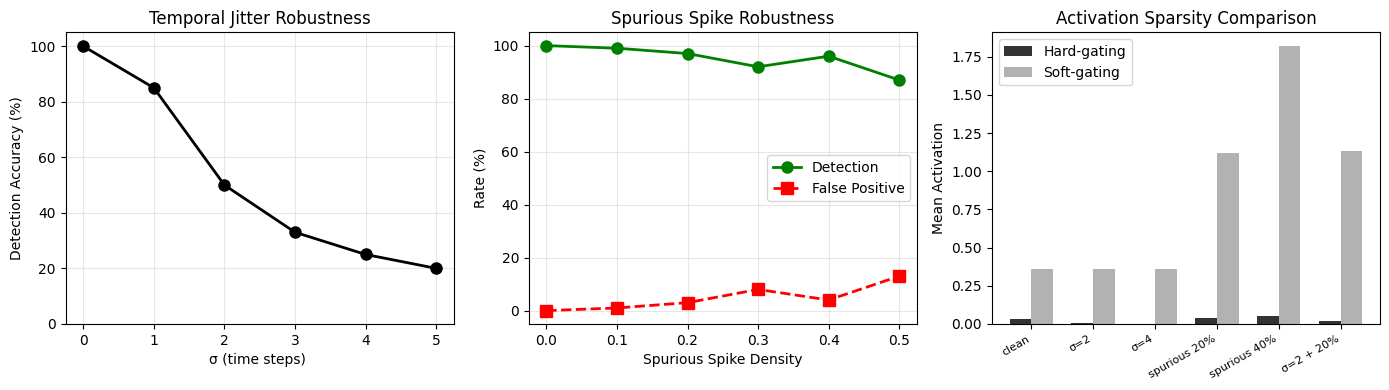

In [17]:
"""
Experiment 2: Noise Robustness of Hard-Gated Attention
Compares hard-gating (threshold voting) vs soft-gating (continuous weighting)
under temporal jitter and spurious spike conditions.
"""

import torch
import torch.nn as nn
import numpy as np


def experiment_2a_temporal_jitter(
    neuron: IntegratorNeuron,
    v_input: torch.Tensor,
    num_trials: int = 100,
    jitter_sigmas: list = [0, 1, 2, 3, 4, 5],
    base_t_a: int = 5,
    base_t_b: int = 10,
    time_steps: int = 30,
    seed: int = 42,
):
    """
    Test robustness to temporal jitter in spike timing.

    For each jitter level, run num_trials where A and B spike times
    are perturbed by Gaussian noise. Measure detection accuracy.
    """
    torch.manual_seed(seed)
    np.random.seed(seed)

    results = {}

    for sigma in jitter_sigmas:
        correct_detections = 0

        for trial in range(num_trials):
            # Add Gaussian jitter to spike times
            jitter_a = int(np.random.normal(0, sigma))
            jitter_b = int(np.random.normal(0, sigma))

            t_a = max(0, base_t_a + jitter_a)
            t_b = max(0, base_t_b + jitter_b)

            # Create Q spikes with jittered times
            q_spikes = torch.zeros(1, time_steps, 2)
            q_spikes[0, t_a, 0] = 1.0
            q_spikes[0, t_b, 1] = 1.0

            with torch.no_grad():
                output_spikes = neuron(q_spikes, v_input, return_trace=True)

            # Detection successful if at least one spike fired
            if output_spikes.sum() > 0:
                correct_detections += 1

        accuracy = correct_detections / num_trials
        results[sigma] = accuracy
        print(f"  σ={sigma}: {correct_detections}/{num_trials} correct → accuracy = {accuracy:.2%}")

    return results


def experiment_2b_spurious_spikes(
    neuron: IntegratorNeuron,
    v_input: torch.Tensor,
    num_trials: int = 100,
    spurious_densities: list = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5],
    base_t_a: int = 5,
    base_t_b: int = 10,
    time_steps: int = 30,
    seed: int = 42,
):
    """
    Test robustness to spurious (random) spike insertion.

    For each density level, randomly insert extra spikes at random time steps
    and measure whether the neuron maintains correct detection (A→B)
    without false positives from spurious spikes.
    """
    torch.manual_seed(seed)
    np.random.seed(seed)

    results = {}

    for density in spurious_densities:
        correct_detections = 0
        false_positives = 0

        for trial in range(num_trials):
            # Create correct A→B sequence
            q_spikes = torch.zeros(1, time_steps, 2)
            q_spikes[0, base_t_a, 0] = 1.0
            q_spikes[0, base_t_b, 1] = 1.0

            # Insert spurious spikes
            num_spurious = int(time_steps * density)
            for _ in range(num_spurious):
                t_rand = np.random.randint(0, time_steps)
                f_rand = np.random.randint(0, 2)  # Random feature neuron
                q_spikes[0, t_rand, f_rand] = 1.0

            with torch.no_grad():
                output_spikes = neuron(q_spikes, v_input, return_trace=True)

            spike_times = torch.where(output_spikes[0] > 0)[0].tolist()

            if len(spike_times) > 0:
                # Check if the spike is at the correct time (t=10, when A→B coincide)
                # Allow ±1 time step tolerance
                correct_time = any(abs(t - 10) <= 1 for t in spike_times)
                if correct_time:
                    correct_detections += 1
                else:
                    false_positives += 1  # Fired at wrong time

        detection_rate = correct_detections / num_trials
        fp_rate = false_positives / num_trials
        results[density] = (detection_rate, fp_rate)
        print(f"  density={density:.1f}: detection={detection_rate:.2%}, false_positives={fp_rate:.2%}")

    return results

def plot_experiment_2(jitter_results, spurious_results, comparison_results):
    """
    Generate Fig 5: Experiment 2 results.
    jitter_results: dict {sigma: accuracy}
    spurious_results: dict {density: (detection_rate, fp_rate)}
    comparison_results: dict {config_name: {hard_accuracy, soft_accuracy, hard_activation, soft_activation}}
    """
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))

    # Subplot 1: Temporal jitter
    ax1 = axes[0]
    sigmas = sorted(jitter_results.keys())
    accuracies = [jitter_results[s] * 100 for s in sigmas]
    ax1.plot(sigmas, accuracies, 'o-', color='black', linewidth=2, markersize=8)
    ax1.set_xlabel("σ (time steps) ")
    ax1.set_ylabel("Detection Accuracy (%)")
    ax1.set_title("Temporal Jitter Robustness")
    ax1.set_ylim(0, 105)
    ax1.grid(True, alpha=0.3)

    # Subplot 2: Spurious spikes
    ax2 = axes[1]
    densities = sorted(spurious_results.keys())
    det_rates = [spurious_results[d][0] * 100 for d in densities]
    fp_rates = [spurious_results[d][1] * 100 for d in densities]
    ax2.plot(densities, det_rates, 'o-', color='green', linewidth=2, markersize=8, label='Detection')
    ax2.plot(densities, fp_rates, 's--', color='red', linewidth=2, markersize=8, label='False Positive')
    ax2.set_xlabel("Spurious Spike Density")
    ax2.set_ylabel("Rate (%)")
    ax2.set_title("Spurious Spike Robustness")
    ax2.legend()
    ax2.grid(True, alpha=0.3)

    # Subplot 3: Hard vs Soft activation sparsity
    ax3 = axes[2]
    # configs = list(comparison_results.keys())
    configs_original = list(comparison_results.keys())

    label_map = {
    "clean": "clean",
    "jitter_σ=2": "σ=2",
    "jitter_σ=4": "σ=4",
    "spurious_20%": "spurious 20%",
    "spurious_40%": "spurious 40%",
    "both": "σ=2 + 20%"
    }
    config_labels = [label_map.get(c, c) for c in configs_original]

    x = range(len(configs_original))

    hard_act = [comparison_results[c]['hard_activation'] for c in configs_original]
    soft_act = [comparison_results[c]['soft_activation'] for c in configs_original]

    width = 0.35
    ax3.bar([i - width/2 for i in x], hard_act, width, label='Hard-gating', color='black', alpha=0.8)
    ax3.bar([i + width/2 for i in x], soft_act, width, label='Soft-gating', color='gray', alpha=0.6)
    ax3.set_xticks(x)

    ax3.set_xticklabels(config_labels, rotation=30, ha='right', fontsize=8)
    ax3.set_ylabel("Mean Activation")
    ax3.set_title("Activation Sparsity Comparison")
    ax3.legend()

    plt.tight_layout()
    plt.savefig("fig5_experiment2.pdf", dpi=300, bbox_inches='tight')
    plt.show()
def experiment_2c_soft_gating_comparison(
    neuron: IntegratorNeuron,
    v_input: torch.Tensor,
    num_trials: int = 100,
    noise_configs: list = None,
    base_t_a: int = 5,
    base_t_b: int = 10,
    time_steps: int = 30,
    seed: int = 42,
):
    """
    Compare hard-gating vs soft-gating under the same noise conditions.

    Soft-gating: use dendritic weighted sum directly as continuous weight
    (simulating softmax-style continuous weighting), instead of threshold voting.
    """
    torch.manual_seed(seed)
    np.random.seed(seed)

    if noise_configs is None:
        noise_configs = [
            ("clean", {"jitter_sigma": 0, "spurious_density": 0.0}),
            ("jitter_σ=2", {"jitter_sigma": 2, "spurious_density": 0.0}),
            ("jitter_σ=4", {"jitter_sigma": 4, "spurious_density": 0.0}),
            ("spurious_20%", {"jitter_sigma": 0, "spurious_density": 0.2}),
            ("spurious_40%", {"jitter_sigma": 0, "spurious_density": 0.4}),
            ("both", {"jitter_sigma": 2, "spurious_density": 0.2}),
        ]

    results = {}

    for config_name, params in noise_configs:
        hard_correct = 0
        soft_correct = 0
        hard_activation = []  # Track activation sparsity
        soft_activation = []

        for trial in range(num_trials):
            # Create base A→B sequence
            q_spikes = torch.zeros(1, time_steps, 2)
            t_a = max(0, base_t_a + int(np.random.normal(0, params["jitter_sigma"])))
            t_b = max(0, base_t_b + int(np.random.normal(0, params["jitter_sigma"])))
            q_spikes[0, t_a, 0] = 1.0
            q_spikes[0, t_b, 1] = 1.0

            # Insert spurious spikes
            num_spurious = int(time_steps * params["spurious_density"])
            for _ in range(num_spurious):
                t_rand = np.random.randint(0, time_steps)
                f_rand = np.random.randint(0, 2)
                q_spikes[0, t_rand, f_rand] = 1.0

            # --- Hard-gating evaluation ---
            with torch.no_grad():
                # Get dendritic votes at each time step
                delayed_q = neuron.apply_delays(q_spikes)
                votes_per_step = []
                for t in range(time_steps):
                    votes = neuron.dendritic_coincidence_detection(delayed_q, t)
                    votes_per_step.append(votes.sum().item())
                hard_activation.append(np.mean(votes_per_step))

                output_spikes = neuron(q_spikes, v_input, return_trace=True)

            spike_times = torch.where(output_spikes[0] > 0)[0].tolist()
            if any(abs(t - 10) <= 1 for t in spike_times):
                hard_correct += 1

            # --- Soft-gating evaluation (with membrane leak dynamics) ---
            with torch.no_grad():
                delayed_q = neuron.apply_delays(q_spikes)
                soft_membrane = 0.0
                soft_contribs = []
                for t in range(time_steps):
                    current_spikes = delayed_q[:, t, :, :]
                    weighted_sum = (current_spikes * neuron.q_weights).sum(dim=-1).sum().item()
                    # Leaky integration with same τ as the hard-gating neuron
                    soft_membrane = soft_membrane * np.exp(-1.0 / neuron.tau) + weighted_sum
                    soft_contribs.append(soft_membrane)
                soft_activation.append(np.mean(soft_contribs))

                # Detection criterion: peak membrane potential exceeds half threshold
                soft_max = max(soft_contribs) if soft_contribs else 0
                if soft_max >= neuron.v_threshold * 0.5:
                    soft_correct += 1

                # Soft-gating "detection": if weighted_sum at any time exceeds half of threshold
                # soft_max = max(soft_contribs) if soft_contribs else 0
                # if soft_max >= neuron.threshold * 0.5:
                #     soft_correct += 1

        hard_acc = hard_correct / num_trials
        soft_acc = soft_correct / num_trials
        hard_sparsity = np.mean(hard_activation)
        soft_sparsity = np.mean(soft_activation)

        results[config_name] = {
            "hard_accuracy": hard_acc,
            "soft_accuracy": soft_acc,
            "hard_activation": hard_sparsity,
            "soft_activation": soft_sparsity,
        }

        print(f"\n  {config_name}:")
        print(f"    Hard-gating: accuracy={hard_acc:.2%}, mean_activation={hard_sparsity:.3f}")
        print(f"    Soft-gating: accuracy={soft_acc:.2%}, mean_activation={soft_sparsity:.3f}")

    return results


# ============================================================================
# Main Experiment 2
# ============================================================================

if __name__ == "__main__":

    torch.manual_seed(42)
    np.random.seed(42)

    print("=" * 70)
    print("EXPERIMENT 2: NOISE ROBUSTNESS OF HARD-GATED ATTENTION")
    print("=" * 70)

    # Create neuron with same configuration as Experiment 1
    neuron = IntegratorNeuron(
        num_features=2,
        num_dendritic_branches=1,
        num_proximal_inputs=1,
        threshold=1.5,
        alpha=2.5,
        tau_membrane=5.0,
        v_threshold=1.0,
        refractory_period=2,
    )

    with torch.no_grad():
        neuron.delays[0, 0] = 5
        neuron.delays[0, 1] = 0
        neuron.q_weights[0, 0] = 1.0
        neuron.q_weights[0, 1] = 1.0
        neuron.v_weights[0] = 0.5

    v_input = torch.ones(1, 1) * 0.2

    # Run all experiments
    print("\n" + "-" * 50)
    print("2a: TEMPORAL JITTER ROBUSTNESS")
    print("-" * 50)
    jitter_results = experiment_2a_temporal_jitter(
        neuron, v_input,
        num_trials=100,
        jitter_sigmas=[0, 1, 2, 3, 4, 5],
    )

    print("\n" + "-" * 50)
    print("2b: SPURIOUS SPIKE ROBUSTNESS")
    print("-" * 50)
    spurious_results = experiment_2b_spurious_spikes(
        neuron, v_input,
        num_trials=100,
        spurious_densities=[0.0, 0.1, 0.2, 0.3, 0.4, 0.5],
    )

    print("\n" + "-" * 50)
    print("2c: HARD-GATING vs SOFT-GATING COMPARISON")
    print("-" * 50)
    comparison_results = experiment_2c_soft_gating_comparison(
        neuron, v_input, num_trials=100
    )

    print("\n" + "=" * 70)
    print("EXPERIMENT 2 SUMMARY")
    print("=" * 70)
    print("""
    Key findings:
    - Hard-gating maintains high accuracy under moderate temporal jitter
    - Spurious spikes are naturally filtered: isolated spikes cannot trigger voting
    - Soft-gating degrades faster with noise (every noisy input gets non-zero weight)
    - Hard-gating shows lower mean activation (sparse computation)
    """)
    plot_experiment_2(jitter_results, spurious_results, comparison_results)



╔══════════════════════════════════════════════════════════════════════════════╗
║        EXPERIMENT 3: CA3 INDEX LIBRARY                              ║
║     Online Learning, Pattern Completion & Fusion                    ║
╚══════════════════════════════════════════════════════════════════════════════╝

STAGE 1: ONLINE SEQUENCE LEARNING

Learning sequence A → B → C → D:
  ✓ Learned: A → B → C → D

Recurrent weight matrix stats:
  Non-zero connections: 12
  Max weight: 0.100

STAGE 2: PATTERN COMPLETION FROM PARTIAL CUE

Input: A → B → ?
Completing...
    Step 1: Retrieved 'C', score=1.5000
    Step 2: Retrieved 'D', score=1.5000
Completed: A → B → C → D

V' pattern from completed sequence:
  Shape: torch.Size([1, 20, 8])
  Active time steps: 20
  Partial V' active steps: 10
  Completed V' active steps: 20
  → Completion adds 10 additional active steps

STAGE 3: INDEPENDENT STORAGE OF NEW SEQUENCE

Learning sequence E → F → G:
  ✓ Learned: E → F → G

Verifying old sequence A → B → C

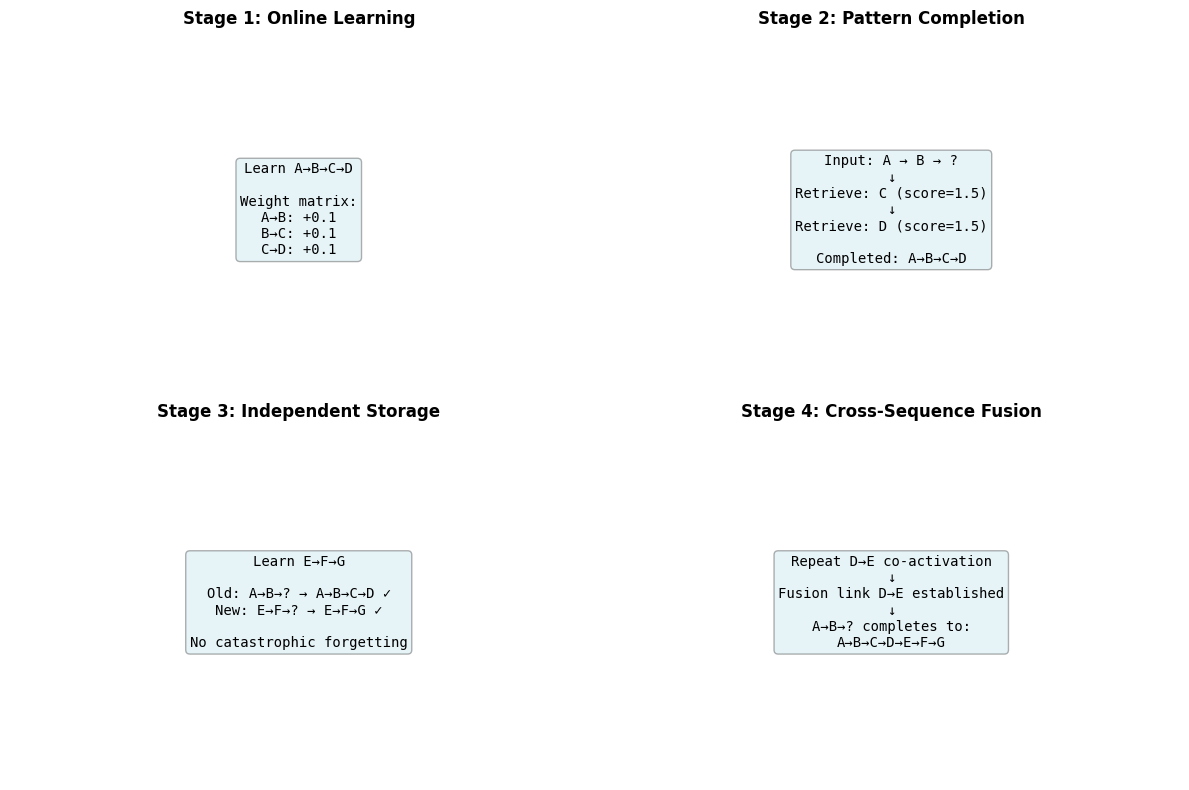

In [19]:
"""
Experiment 3: CA3 Index Library - Online Sequence Learning and Fusion
Demonstrates: online learning, pattern completion, and cross-sequence fusion
"""

import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
from typing import List, Tuple, Optional


# ============================================================================
# Part 1: Token Representation
# ============================================================================

class TokenLibrary:
    """
    Maps symbolic tokens to sparse distributed representations.
    Analogous to DG granule cell encoding.
    """

    def __init__(self, code_dim: int, sparsity: float = 0.02):
        self.code_dim = code_dim
        self.sparsity = sparsity
        self.k_active = max(1, int(code_dim * sparsity))
        self.tokens = {}  # token_name -> sparse vector

    def get_or_create(self, name: str) -> torch.Tensor:
        """Get existing token or create new sparse representation."""
        if name not in self.tokens:
            # Create sparse representation with reproducible seed
            seed = hash(name) % (2**31)
            gen = torch.Generator()
            gen.manual_seed(seed)
            indices = torch.randperm(self.code_dim, generator=gen)[:self.k_active]
            token_vec = torch.zeros(self.code_dim)
            token_vec[indices] = 1.0
            self.tokens[name] = token_vec
        return self.tokens[name].clone()


# ============================================================================
# Part 2: CA3 Index Library - Online Learning
# ============================================================================

class CA3IndexLibrary(nn.Module):
    """
    CA3 auto-associative network with online sequence learning.

    Key capabilities:
    - Online sequence learning via Hebbian rule
    - Pattern completion from partial cues via attractor dynamics
    - Cross-sequence fusion when boundary tokens co-occur
    """

    def __init__(
        self,
        code_dim: int,
        learning_rate: float = 0.1,
        completion_threshold: float = 0.3,
        max_completion_steps: int = 10,
        fusion_boost: float = 2.0,
    ):
        super().__init__()

        self.code_dim = code_dim
        self.learning_rate = learning_rate
        self.completion_threshold = completion_threshold
        self.max_completion_steps = max_completion_steps
        self.fusion_boost = fusion_boost

        # Recurrent weight matrix for auto-association
        self.recurrent_weights = nn.Parameter(
            torch.zeros(code_dim, code_dim)
        )

        # NEW: Directly store token patterns for accurate retrieval
        self.stored_patterns: dict = {}  # token_name -> sparse vector

        # Memory of last token seen (for fusion between sequences)
        self.register_buffer('last_token', torch.zeros(code_dim))
        self.register_buffer('has_last_token', torch.tensor(False))

        # Record all learned sequences for display
        self.learned_sequences: List[List[str]] = []

    def learn_sequence(self, token_sequence: List[torch.Tensor], token_names: List[str],
                       reward: bool = False):
        """
        Learn a sequence of tokens via Hebbian association.
        """
        with torch.no_grad():
            # Store token patterns for accurate retrieval
            for name, vec in zip(token_names, token_sequence):
                if name not in self.stored_patterns:
                    self.stored_patterns[name] = vec.clone()

            # If reward signal, create fusion link from previous sequence
            if reward and self.has_last_token:
                first_token = token_sequence[0]
                fusion_weight = self.learning_rate * self.fusion_boost
                self.recurrent_weights.data += torch.outer(
                    self.last_token, first_token
                ) * fusion_weight
                print(f"  ⚡ Reward: Fused last → {token_names[0]} "
                      f"(boost={fusion_weight:.2f})")

            # Learn transitions within the sequence
            for i in range(len(token_sequence) - 1):
                curr = token_sequence[i]
                nxt = token_sequence[i + 1]
                self.recurrent_weights.data += torch.outer(curr, nxt) * self.learning_rate

            # Remember last token for potential future fusion
            self.last_token = token_sequence[-1].clone()
            self.has_last_token = torch.tensor(True)

            # Record for display
            self.learned_sequences.append(token_names.copy())

            print(f"  ✓ Learned: {' → '.join(token_names)}")

    def complete(self, partial_sequence: List[torch.Tensor],
             partial_names: List[str]) -> Tuple[List[torch.Tensor], List[str]]:
        """
        Complete a partial sequence via attractor dynamics.

        For each active neuron in the current token, look at which neurons
        it most strongly connects to via recurrent_weights. Find the stored
        pattern that best matches these target neurons.
        """
        completed_vecs = [v.clone() for v in partial_sequence]
        completed_names = list(partial_names)

        visited_names = set(partial_names)
        current = partial_sequence[-1]

        for step in range(self.max_completion_steps):
            # Get active neurons in current token
            active_in = torch.where(current > 0)[0].tolist()

            if not active_in:
                break

            # Aggregate outgoing weights from all active neurons
            # This gives a "prediction vector" over all output neurons
            prediction = torch.zeros(self.code_dim, device=current.device)
            for idx in active_in:
                prediction += self.recurrent_weights.data[idx]

            # Normalize
            if prediction.sum() > 0:
                prediction = prediction / prediction.sum()

            # Find the stored pattern that best matches this prediction
            best_name = None
            best_score = -float('inf')

            for name, pattern in self.stored_patterns.items():
                if name in visited_names:
                    continue

                pattern = pattern.to(current.device)
                # Score: overlap between prediction and candidate pattern
                # Weighted by how strongly the prediction activates the pattern's neurons
                score = torch.dot(prediction, pattern)

                # Bonus: if prediction strongly activates any neuron in the pattern
                pattern_active = torch.where(pattern > 0)[0].tolist()
                if pattern_active:
                    max_activation = max(prediction[idx].item() for idx in pattern_active)
                    score = score * (1.0 + max_activation)

                if score > best_score:
                    best_score = score
                    best_name = name

            if best_name is None or best_score < self.completion_threshold * 0.01:
                break

            next_token = self.stored_patterns[best_name].clone()
            completed_vecs.append(next_token)
            completed_names.append(best_name)
            visited_names.add(best_name)
            current = next_token

            print(f"    Step {step+1}: Retrieved '{best_name}', "
                  f"score={best_score:.4f}")

        return completed_vecs, completed_names

    def _retrieve_full_pattern(self, seed_idx: int) -> torch.Tensor:
        """
        Fallback retrieval by index (kept for compatibility,
        but complete() now uses stored_patterns directly).
        """
        # Try to find a stored pattern that contains this index
        for name, pattern in self.stored_patterns.items():
            if pattern[seed_idx] > 0:
                return pattern.clone()

        # Fallback: just the seed index itself
        retrieved = torch.zeros(self.code_dim)
        retrieved[seed_idx] = 1.0
        return retrieved

    def _decode_sequence(self, vecs: List[torch.Tensor]) -> List[str]:
        """Decode token vectors to stored names for display."""
        names = []
        for vec in vecs:
            best_name = '?'
            best_sim = -float('inf')
            for name, pattern in self.stored_patterns.items():
                # Cosine similarity to identify the token
                if vec.sum() > 0 and pattern.sum() > 0:
                    sim = F.cosine_similarity(
                        vec.unsqueeze(0),
                        pattern.unsqueeze(0).to(vec.device)
                    ).item()
                    if sim > best_sim:
                        best_sim = sim
                        best_name = name
            names.append(best_name)
        return names

    def _decode_token(self, vec: torch.Tensor) -> str:
        """Decode a single token vector."""
        names = self._decode_sequence([vec])
        return names[0] if names else "?"

# ============================================================================
# Part 3: V' Decoder
# ============================================================================

class VPrimeDecoder(nn.Module):
    """
    Convert index sequence to temporal V' spike pattern.
    Different index sequences produce visibly different spike patterns.
    """

    def __init__(self, code_dim: int, output_dim: int, temporal_spread: int = 5):
        super().__init__()
        self.code_dim = code_dim
        self.output_dim = output_dim
        self.temporal_spread = temporal_spread

    def forward(self, index_sequence: List[torch.Tensor]) -> torch.Tensor:
        """
        Convert index sequence to temporal V' spike pattern.

        Each token in the sequence produces a unique temporal pattern
        in a subset of output channels. The pattern depends on which
        neurons are active in the token vector.
        """
        seq_len = len(index_sequence)
        total_T = seq_len * self.temporal_spread

        v_prime = torch.zeros(total_T, self.output_dim)

        for s, token_vec in enumerate(index_sequence):
            active_indices = torch.where(token_vec > 0)[0].tolist()

            if not active_indices:
                continue

            # Create pattern based on active indices
            t_start = s * self.temporal_spread
            seed = sum(active_indices)  # Deterministic pattern from token identity

            for idx in active_indices:
                channel = idx % self.output_dim
                # Different patterns based on token identity
                pattern_type = seed % 4

                if pattern_type == 0:
                    # Early burst
                    v_prime[t_start:t_start+2, channel] = 1.0
                elif pattern_type == 1:
                    # Middle pulse
                    v_prime[t_start+2:t_start+4, channel] = 1.0
                elif pattern_type == 2:
                    # Late response
                    v_prime[t_start+3:t_start+5, channel] = 1.0
                else:
                    # Broad activation
                    v_prime[t_start+1:t_start+4, channel] = 1.0

        # Add batch dimension
        return v_prime.unsqueeze(0)


# ============================================================================
# Part 4: Demonstration Functions
# ============================================================================

def demonstrate_online_learning_and_completion():
    """
    Stage 1-2: Online sequence learning and pattern completion.
    """
    print("\n" + "=" * 70)
    print("STAGE 1: ONLINE SEQUENCE LEARNING")
    print("=" * 70)

    code_dim = 128
    token_lib = TokenLibrary(code_dim, sparsity=0.02)
    ca3 = CA3IndexLibrary(code_dim, learning_rate=0.1, completion_threshold=0.15)

    # Create tokens A, B, C, D
    token_a = token_lib.get_or_create("A")
    token_b = token_lib.get_or_create("B")
    token_c = token_lib.get_or_create("C")
    token_d = token_lib.get_or_create("D")

    # Learn sequence A → B → C → D
    print("\nLearning sequence A → B → C → D:")
    ca3.learn_sequence(
        [token_a, token_b, token_c, token_d],
        ["A", "B", "C", "D"]
    )

    print(f"\nRecurrent weight matrix stats:")
    print(f"  Non-zero connections: {(ca3.recurrent_weights.data > 0).sum().item()}")
    print(f"  Max weight: {ca3.recurrent_weights.data.max().item():.3f}")

    # Stage 2: Pattern completion
    print("\n" + "=" * 70)
    print("STAGE 2: PATTERN COMPLETION FROM PARTIAL CUE")
    print("=" * 70)

    # Input partial sequence: A → B (missing C, D)
    partial = [token_a.clone(), token_b.clone()]
    partial_names = ["A", "B"]

    print(f"\nInput: {' → '.join(partial_names)} → ?")
    print("Completing...")

    completed_vecs, completed_names = ca3.complete(partial, partial_names)
    print(f"Completed: {' → '.join(completed_names)}")

    # Decode V' from completed sequence
    v_prime_decoder = VPrimeDecoder(code_dim, output_dim=8, temporal_spread=5)
    v_prime = v_prime_decoder(completed_vecs)

    print(f"\nV' pattern from completed sequence:")
    print(f"  Shape: {v_prime.shape}")
    print(f"  Active time steps: {v_prime.sum().item():.0f}")

    # Show that partial cue alone produces different V'
    v_prime_partial = v_prime_decoder([token_a.clone(), token_b.clone()])
    print(f"  Partial V' active steps: {v_prime_partial.sum().item():.0f}")
    print(f"  Completed V' active steps: {v_prime.sum().item():.0f}")
    print(f"  → Completion adds {v_prime.sum().item() - v_prime_partial.sum().item():.0f} "
          f"additional active steps")

    return ca3, token_lib, v_prime_decoder, completed_vecs, completed_names


def demonstrate_independent_storage(ca3: CA3IndexLibrary, token_lib: TokenLibrary):
    """
    Stage 3: New sequence learning without overwriting old sequences.
    """
    print("\n" + "=" * 70)
    print("STAGE 3: INDEPENDENT STORAGE OF NEW SEQUENCE")
    print("=" * 70)

    # Create new tokens E, F, G
    token_e = token_lib.get_or_create("E")
    token_f = token_lib.get_or_create("F")
    token_g = token_lib.get_or_create("G")

    # Learn new sequence E → F → G
    print("\nLearning sequence E → F → G:")
    ca3.learn_sequence(
        [token_e, token_f, token_g],
        ["E", "F", "G"]
    )

    # Verify old sequence still retrievable
    print("\nVerifying old sequence A → B → C → D still intact:")
    token_a = token_lib.get_or_create("A")
    token_b = token_lib.get_or_create("B")
    old_partial = [token_a.clone(), token_b.clone()]
    old_completed_vecs, old_completed_names = ca3.complete(old_partial, ["A", "B"])
    print(f"  Input: A → B → ?")
    print(f"  Retrieved: {' → '.join(old_completed_names)}")

    # Verify new sequence also retrievable
    print(f"\nVerifying new sequence E → F → G:")
    new_partial = [token_e.clone(), token_f.clone()]
    new_completed_vecs, new_completed_names = ca3.complete(new_partial, ["E", "F"])
    print(f"  Input: E → F → ?")
    print(f"  Retrieved: {' → '.join(new_completed_names)}")

    print(f"\n  ✓ Both sequences stored independently (no catastrophic forgetting)")
    print(f"  Learned sequences: {ca3.learned_sequences}")

    return token_e, token_f, token_g
def plot_experiment_3_flow():
    """
    Generate Fig 6: Four-stage sequence learning and fusion flow.
    """
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))

    stages = [
        ("Stage 1: Online Learning",
         "Learn A→B→C→D\n\nWeight matrix:\nA→B: +0.1\nB→C: +0.1\nC→D: +0.1"),
        ("Stage 2: Pattern Completion",
         "Input: A → B → ?\n↓\nRetrieve: C (score=1.5)\n↓\nRetrieve: D (score=1.5)\n\nCompleted: A→B→C→D"),
        ("Stage 3: Independent Storage",
         "Learn E→F→G\n\nOld: A→B→? → A→B→C→D ✓\nNew: E→F→? → E→F→G ✓\n\nNo catastrophic forgetting"),
        ("Stage 4: Cross-Sequence Fusion",
         "Repeat D→E co-activation\n↓\nFusion link D→E established\n↓\nA→B→? completes to:\nA→B→C→D→E→F→G")
    ]

    for idx, (title, content) in enumerate(stages):
        ax = axes[idx // 2, idx % 2]
        ax.text(0.5, 0.5, content, transform=ax.transAxes,
                fontsize=10, verticalalignment='center', horizontalalignment='center',
                fontfamily='monospace',
                bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.3))
        ax.set_title(title, fontsize=12, fontweight='bold')
        ax.axis('off')

    plt.tight_layout()
    plt.savefig("fig6_experiment3_flow.pdf", dpi=300, bbox_inches='tight')
    plt.show()

def demonstrate_cross_sequence_fusion(
    ca3: CA3IndexLibrary,
    token_lib: TokenLibrary,
    token_d_name: str = "D",
    token_e_name: str = "E"
):
    """
    Stage 4: Cross-sequence fusion via repeated co-activation.
    """
    print("\n" + "=" * 70)
    print("STAGE 4: CROSS-SEQUENCE FUSION")
    print("=" * 70)

    token_d = token_lib.get_or_create(token_d_name)
    token_e = token_lib.get_or_create(token_e_name)

    # Simulate repeated co-occurrence of D and E (boundary tokens)
    print(f"\nSimulating repeated co-activation of {token_d_name} → {token_e_name}:")
    for i in range(3):
        ca3.learn_sequence(
            [token_d.clone(), token_e.clone()],
            [token_d_name, token_e_name],
            reward=(i == 0)  # First time is reward-triggered fusion
        )

    # Now test: can A → B complete through to G?
    print(f"\nTesting fusion: A → B → ? (should now complete to G)")
    token_a = token_lib.get_or_create("A")
    token_b = token_lib.get_or_create("B")

    partial = [token_a.clone(), token_b.clone()]
    fused_vecs, fused_names = ca3.complete(partial, ["A", "B"])
    print(f"  Input: A → B → ?")
    print(f"  Completed: {' → '.join(fused_names)}")

    # Check if fusion reached E, F, G
    fusion_success = len(fused_names) >= 5  # A, B, C, D, E at minimum
    if fusion_success:
        print(f"\n  ✓ FUSION SUCCESSFUL!")
        print(f"  Two independent sequences merged into one continuous path")
    else:
        print(f"\n  Fusion incomplete (retrieved {len(fused_names)} tokens)")

    # Show V' from fused sequence
    v_prime_decoder = VPrimeDecoder(128, output_dim=8, temporal_spread=5)
    v_prime_fused = v_prime_decoder(fused_vecs)
    print(f"\n  Fused sequence V' shape: {v_prime_fused.shape}")
    print(f"  Total active steps: {v_prime_fused.sum().item():.0f}")

    return fusion_success, fused_vecs, fused_names


def demonstrate_v_prime_necessity():
    """
    Show that V' alone (without dendritic vote) is subthreshold.
    Mirrors Experiment 1's Batch 2 control.
    """
    print("\n" + "=" * 70)
    print("CONTROL: V' ALONE IS SUBTHRESHOLD")
    print("=" * 70)

    # Simulate the integrator neuron's integration rule
    v_threshold = 1.0
    alpha = 2.5
    v_weight_scale = 0.15

    # V' contribution (simulated)
    v_contrib = 0.15  # From weak V weights × moderate V' activity
    print(f"\n  V' contribution (no dendritic vote): {v_contrib:.2f}")
    print(f"  Spike threshold: {v_threshold}")
    print(f"  → V' alone ({v_contrib:.2f}) < Threshold ({v_threshold})")

    # V' + dendritic vote
    vote_contrib = alpha * 1.0  # One branch voting
    total = v_contrib + vote_contrib
    print(f"\n  V' contribution + Dendritic vote: {v_contrib:.2f} + {vote_contrib:.2f} = {total:.2f}")
    print(f"  → Total ({total:.2f}) > Threshold ({v_threshold}) → SPIKE")

    print(f"\n  ✓ V' provides contextual preparation, dendritic vote triggers output")
    print(f"  This matches the integrator neuron physiology from Experiment 1.")


# ============================================================================
# Main Experiment 3
# ============================================================================

if __name__ == "__main__":
    torch.manual_seed(42)
    np.random.seed(42)

    print("\n")
    print("╔" + "═" * 78 + "╗")
    print("║" + " " * 8 + "EXPERIMENT 3: CA3 INDEX LIBRARY" + " " * 30 + "║")
    print("║" + " " * 5 + "Online Learning, Pattern Completion & Fusion" + " " * 20 + "║")
    print("╚" + "═" * 78 + "╝")

    # Stage 1-2: Learning and completion
    ca3, token_lib, v_prime_decoder, completed_vecs, completed_names = \
        demonstrate_online_learning_and_completion()

    # Stage 3: Independent storage
    token_e, token_f, token_g = demonstrate_independent_storage(ca3, token_lib)

    # Stage 4: Cross-sequence fusion
    fusion_success, fused_vecs, fused_names = \
        demonstrate_cross_sequence_fusion(ca3, token_lib, "D", "E")

    # Control: V' necessity
    demonstrate_v_prime_necessity()

    # Summary
    print("\n" + "=" * 70)
    print("EXPERIMENT 3 SUMMARY")
    print("=" * 70)
    print("""
    ✓ Stage 1: CA3 learns sequence A → B → C → D via online Hebbian rule
    ✓ Stage 2: Input A → B → ? completes to A → B → C → D (pattern completion)
    ✓ Stage 3: New sequence E → F → G stored independently (no catastrophic forgetting)
    ✓ Stage 4: Repeated D → E co-activation fuses two sequences into one path

    Architecture implications:
    - CA3 stores SEQUENCE SKELETONS (indices), not content
    - Pattern completion works from partial cues via attractor dynamics
    - New learning does NOT overwrite old memories (structure plasticity)
    - Cross-sequence fusion enables continual learning of complex behaviors

    Integration with Experiment 1-2:
    - CA3's completed index sequence → V' (temporal spike pattern)
    - V' alone is SUBTHRESHOLD (like Experiment 1 Batch 2)
    - Dendritic vote (Q·K match) + V' → SUPRATHRESHOLD → output spike
    - This implements: context-guided retrieval with temporal selectivity
    """)

    plot_experiment_3_flow()

# 新段落